In [61]:
# New version of the LQG simulation script

import numpy as np
from src.LQG_controller import compute_finite_horizon_lqr_gains, finite_horizon_kalman_gains
from src.simulate_lqg import simulate_lqg, simulate_robust_lqg
from src.sdp_solver import solve_sdp
from src.simulation_plots import simulate_and_plot_average_trajectories


# --- Parameters ---
time_horizon = 30.0  # Total time 
dt = 1.0   # Time step
T = int(time_horizon / dt)  # Number of steps 

# System dimensions
n = 2  # Number of states, to chnage if needed !!
m = 1  # Number of control inputs

# --- System Matrices ---
theta = np.diag([0.15, 0.10])  #mean reversion coefficient for each state, to adapt if needed !!
A = np.eye(n) - theta * dt     # Dynamics matrix (n x n)
B = -dt * np.ones((n, m))      # Control input matrix (n x m)
C = np.eye(n)               # Measurement matrix (p x n) (measures first state)

# --- Initial State and Noise Covariances ---
mu = np.array([[130.0], [100.0]]) 		        # To adapt if needed !! Multiple dimensions possible !	
sigma_x0 = 2.0                     		# Initial state uncertainty
X0_hat = sigma_x0**2 * np.eye(n)   		# Initial state covariance (n x n)
sigma_w = 2.0                      		# Process noise intensity
W_hat = sigma_w**2 * dt * np.eye(n) 	# Process noise covariance (n x n)
sigma_v = 2.0                       	# Measurement noise intensity
V_hat = sigma_v**2 * np.eye(n)      	# Measurement noise covariance (p x p) 

# --- Cost Matrices ---
Q = 4 * np.eye(n)  # State cost (penalize state deviations)
R = 2 * np.eye(m)  # Control cost (penalize large inputs)

# --- Compute Nominal LQR and Kalman Gains ---
K_list = compute_finite_horizon_lqr_gains(A, B, Q, R, T=T)         # LQR gain (m x n)
L_list, _ = finite_horizon_kalman_gains(A, C, W_hat, V_hat, X0_hat, T)

# --- Solve SDP for Robust Covariances ---
sdp_result = solve_sdp(A, B, C, X0_hat, W_hat, V_hat, dt, T, rho_x0=1.0, rho_w=10.0, rho_v=10.0)
X0_robust = sdp_result["X0"]  # Robust initial covariance (n x n)
W0_robust = sdp_result["W0"]  # Robust process noise covariance (n x n)
V0_robust = sdp_result["V0"]  # Robust measurement noise covariance (p x p)

# --- Compute Robust Kalman Gain ---
L_rob, _ = finite_horizon_kalman_gains(A, C, W0_robust, V0_robust, X0_robust, T) 



In [62]:
print("SDP status:", sdp_result["status"])
print("\nOptimal value:", sdp_result["optimal_value"])
print("X0_robust:\n", X0_robust)
print("W0_robust:\n", W0_robust)
print("V0_robust:\n", V0_robust)


SDP status: optimal

Optimal value: 17180.023466095
X0_robust:
 [[ 6.89180926 -1.02370233]
 [-1.02370233  7.53338008]]
W0_robust:
 [[ 67.94898879 -62.09956722]
 [-62.09956722  86.61745345]]
V0_robust:
 [[55.65886727 64.93536811]
 [64.93536811 95.22491013]]


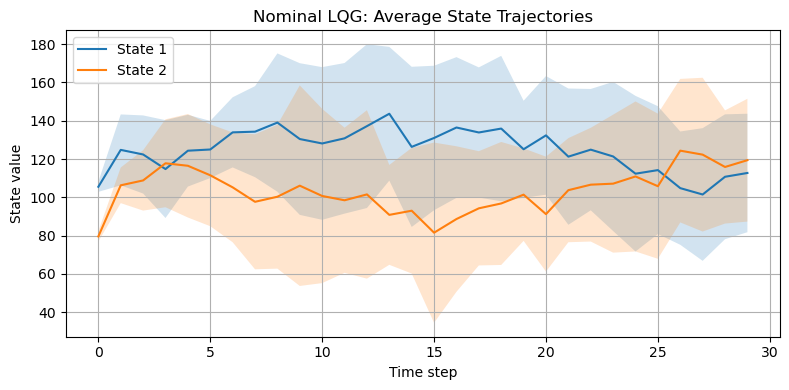

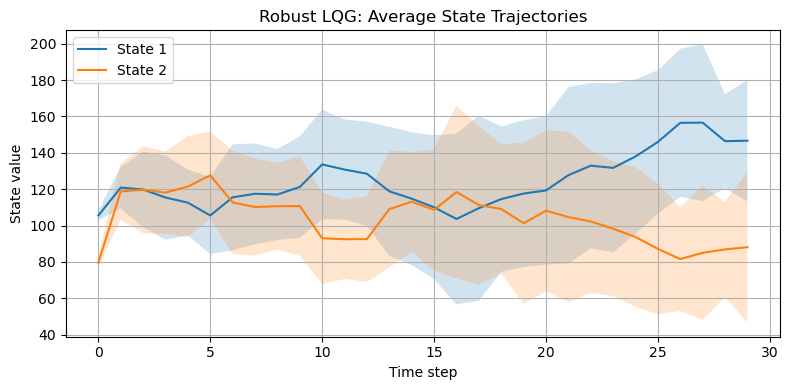

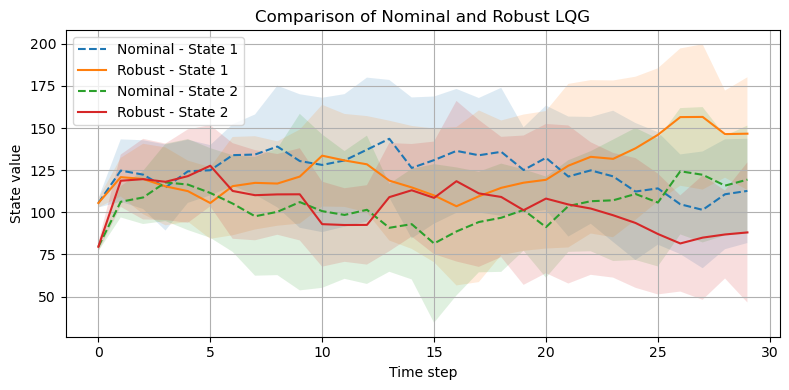

(array([[105.50725042,  79.57531634],
        [124.77619258, 106.27367069],
        [122.37634238, 108.82174423],
        [114.75145279, 117.77529288],
        [124.34482178, 116.47575923],
        [124.97890308, 111.50950033],
        [133.92783024, 105.21463598],
        [134.29029878,  97.66152792],
        [139.02970245, 100.30952561],
        [130.43689708, 106.08129087],
        [128.1220842 , 100.70518442],
        [130.80896936,  98.45816676],
        [137.17826255, 101.51857409],
        [143.64631694,  90.8357831 ],
        [126.35045066,  93.0059158 ],
        [130.99722544,  81.53181967],
        [136.46168524,  88.65978182],
        [133.86301761,  94.25376476],
        [135.90388506,  96.79641572],
        [125.10940508, 101.39132485],
        [132.34936118,  91.22676855],
        [121.24533588, 103.73335459],
        [124.89683433, 106.60298293],
        [121.3412374 , 107.13755796],
        [112.3429269 , 110.89936148],
        [114.21071093, 105.8011696 ],
        [104

In [65]:
W_real = 4 * W0_robust  # Test process noise covariance
V_real = 4 * V0_robust  # Test measurement noise covariance

simulate_and_plot_average_trajectories(
    T,A, B, C, mu,
    K_list, L_list,
    K_list_rob=K_list,     
    L_list_rob=L_rob,
    X0_robust=X0_robust,
    W_test=W_real,
    V_test=V_real,
    initial_point = 0.80 * mu,  # Initial state
    N_runs=10,
)

